In [ ]:
!pip -q install datasets
from datasets import load_dataset

ds = load_dataset("changelinglab/easycall-dysarthria")
print(ds)

README.md:   0%|          | 0.00/3.58k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  136MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  295MB            

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  295MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

... (12 outputs left out)

Generating train split:   0%|          | 0/11901 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4272 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4272 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['audio', 'filename', 'speaker', 'text', 'dysarthria_severity'],
        num_rows: 5213
    })
    train: Dataset({
        features: ['audio', 'filename', 'speaker', 'text', 'dysarthria_severity'],
        num_rows: 11901
    })
    validation: Dataset({
        features: ['audio', 'filename', 'speaker', 'text', 'dysarthria_severity'],
        num_rows: 4272
    })
})
DatasetDict({
    test: Dataset({
        features: ['audio', 'filename', 'speaker', 'text', 'dysarthria_severity'],
        num_rows: 5213
    })
    train: Dataset({
        features: ['audio', 'filename', 'speaker', 'text', 'dysarthria_severity'],
        num_rows: 11901
    })
    validation: Dataset({
        features: ['audio', 'filename', 'speaker', 'text', 'dysarthria_severity'],
        num_rows: 4272
    })
})


In [ ]:
import pandas as pd
from datasets import concatenate_datasets

full = concatenate_datasets([ds["train"], ds["validation"], ds["test"]])

meta = full.remove_columns("audio").to_pandas()
meta["session"] = meta["filename"].str.split("_").str[1]
meta["word"] = meta["text"].str.lower().str.strip()

print(len(meta), "clips")
print(meta["speaker"].nunique(), "speakers")
print(meta["word"].nunique(), "different words")

print("\nSpeakers at each severity level:")
print(meta.groupby("dysarthria_severity")["speaker"].nunique())

print("\nSessions per speaker:")
print(meta.groupby("speaker")["session"].nunique().sort_values().to_string())

print("\nClips per word:")
print(meta["word"].value_counts().to_string())

21386 clips
55 speakers
71 different words

Speakers at each severity level:
dysarthria_severity
0      24
1      16
2       8
3       6
N/A     1
Name: speaker, dtype: int64

Sessions per speaker:
speaker
f10     2
m16     2
m19     3
f04     4
m14     4
f11     5
f01     5
f05     6
f08     6
f07     6
f09     6
fc01    6
fc02    6
f06     6
f02     6
f03     6
m08     6
fc07    6
fc09    6
fc10    6
m02     6
m01     6
m03     6
m04     6
m10     6
m05     6
m06     6
m07     6
m11     6
fc03    6
fc04    6
fc06    6
mc12    6
mc13    6
m09     6
m12     6
m15     6
m13     6
m17     6
m18     6
m20     6
mc01    6
mc02    6
mc03    6
mc04    6
mc06    6
mc09    6
mc08    6
mc14    6
mc11    6
mc10    6
mc05    7
mc07    7
fc05    8
fc08    8

Clips per word:
word
nuovo contatto                318
otto                          318
deseleziona                   318
sette                         318
uno                           317
chiudi                        317
chiamata          

In [ ]:
meta["word"] = (
    meta["word"]
    .str.replace("’", " ", regex=False)
    .str.replace("'", " ", regex=False)
    .str.replace(r"\s+\d+$", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(meta["word"].nunique(), "words after cleanup")
print(meta["word"].value_counts().tail(5).to_string())

print("\nspeakers per severity")
print(meta.groupby("dysarthria_severity")["speaker"].nunique().to_string())

print("\nsessions per speaker")
print(meta.groupby("speaker")["session"].nunique().sort_values().to_string())

67 words after cleanup
word
sotto                    315
scorri verso il basso    315
richiama                 315
scorri verso l alto      315
esci da rubrica          173

speakers per severity
dysarthria_severity
0      24
1      16
2       8
3       6
N/A     1

sessions per speaker
speaker
f10     2
m16     2
m19     3
f04     4
m14     4
f11     5
f01     5
f05     6
f08     6
f07     6
f09     6
fc01    6
fc02    6
f06     6
f02     6
f03     6
m08     6
fc07    6
fc09    6
fc10    6
m02     6
m01     6
m03     6
m04     6
m10     6
m05     6
m06     6
m07     6
m11     6
fc03    6
fc04    6
fc06    6
mc12    6
mc13    6
m09     6
m12     6
m15     6
m13     6
m17     6
m18     6
m20     6
mc01    6
mc02    6
mc03    6
mc04    6
mc06    6
mc09    6
mc08    6
mc14    6
mc11    6
mc10    6
mc05    7
mc07    7
fc05    8
fc08    8


In [ ]:
!pip -q install datasets
import numpy as np
from datasets import load_dataset, concatenate_datasets, Audio

ds = load_dataset("changelinglab/easycall-dysarthria")
full = concatenate_datasets([ds["train"], ds["validation"], ds["test"]]).cast_column("audio", Audio(sampling_rate=16000))

seconds = np.array([len(row["audio"]["array"]) / 16000 for row in full])
too_short, too_long = seconds < 0.2, seconds > 30
print("recordings:", len(seconds))
print("too short (under 0.2 seconds):", too_short.sum())
print("too long (over 30 seconds):", too_long.sum())
print("removed:", (too_short | too_long).sum())

recordings: 21386
too short (under 0.2 seconds): 24
too long (over 30 seconds): 12
removed: 36


In [ ]:
import pickle, torch, librosa
import numpy as np
import torch.nn.functional as F
from tqdm.auto import tqdm
from numba import njit, prange
from datasets import Audio as HFAudio
from transformers import WhisperFeatureExtractor, WhisperModel

full = full.cast_column("audio", HFAudio(sampling_rate=16000))
fe = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")
listener = WhisperModel.from_pretrained("openai/whisper-small", torch_dtype=torch.float16).encoder.to("cuda").eval()

@njit(parallel=True, fastmath=True)
def dtw_many(q, T, lens):
    out = np.empty(len(T), dtype=np.float32)
    n = len(q)
    for k in prange(len(T)):
        m = lens[k]
        cost = 1.0 - q @ np.ascontiguousarray(T[k, :m]).T
        D = np.full((n + 1, m + 1), np.inf, dtype=np.float32)
        D[0, 0] = 0.0
        for i in range(1, n + 1):
            for j in range(1, m + 1):
                D[i, j] = cost[i - 1, j - 1] + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
        out[k] = D[n, m] / (n + m)
    return out

level = meta["dysarthria_severity"].astype(str)
counts = meta.groupby("speaker")["session"].nunique()
who = [s for s in counts[counts >= 4].index if level[meta["speaker"] == s].iloc[0] in ["1", "2", "3"]]

dist = {}
for spk in tqdm(who):
    seq, dur, loud = {}, {}, {}
    ids = meta.index[meta["speaker"] == spk].values
    for start in range(0, len(ids), 32):
        batch, clips, spans = [], [], []
        for i in ids[start:start + 32]:
            x = np.asarray(full[int(i)]["audio"]["array"], dtype=np.float32)
            if not 0.2 <= len(x) / 16000 <= 30:
                continue
            dur[i], loud[i] = len(x) / 16000, float(np.sqrt((x ** 2).mean()))
            spans.append(tuple(librosa.effects.trim(x, top_db=30)[1])); clips.append(x); batch.append(i)
        if not clips:
            continue
        feats = fe(clips, sampling_rate=16000, return_tensors="pt").input_features.to("cuda", torch.float16)
        with torch.no_grad():
            heard = listener(feats).last_hidden_state.float()
        for row, i in enumerate(batch):
            first = min(spans[row][0] // 320, 1498)
            last = max(first + 2, min(1500, -(-spans[row][1] // 320)))
            steps = int(min(200, max(1, (last - first) // 2)))
            seq[i] = F.adaptive_avg_pool1d(heard[row, first:last].T[None], steps)[0].T.cpu().numpy()

    g = meta.loc[sorted(seq)].sort_values("session")
    sessions = sorted(g["session"].unique())
    saved = g[g["session"].isin(sessions[:3])].groupby("word").head(3)
    test = g[g["session"].isin(sessions[3:])]

    frames = np.concatenate([seq[i] for i in saved.index])
    mid, spread = frames.mean(0), frames.std(0) + 1e-6
    def prep(i):
        z = (seq[i] - mid) / spread
        return np.ascontiguousarray(z / np.linalg.norm(z, axis=1, keepdims=True), dtype=np.float32)

    S = [prep(i) for i in saved.index]
    lens = np.array([len(z) for z in S])
    T = np.zeros((len(S), lens.max(), 768), dtype=np.float32)
    for k, z in enumerate(S):
        T[k, :len(z)] = z

    dist[spk] = {
        "sev": level[saved.index[0]],
        "saved_clip": saved.index.values, "saved_word": saved["word"].values, "saved_session": saved["session"].values,
        "test_clip": test.index.values, "test_word": test["word"].values, "test_session": test["session"].values,
        "test_dur": np.array([dur[i] for i in test.index]), "test_loud": np.array([loud[i] for i in test.index]),
        "D_test": np.stack([dtw_many(prep(i), T, lens) for i in test.index]),
        "D_saved": np.stack([dtw_many(z, T, lens) for z in S]),
    }
    pickle.dump(dist, open("dist.pkl", "wb"))

hits = sum((d["saved_word"][d["D_test"].argmin(1)] == d["test_word"]).sum() for d in dist.values())
total = sum(len(d["test_word"]) for d in dist.values())
print("right:", round(hits / total, 3), "on", total, "clips from", len(dist), "speakers")

from google.colab import files
files.download("dist.pkl")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

right: 0.724 on 5149 clips from 27 speakers


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

In [ ]:
def build_tables(speakers):
    tables = {}
    for spk in tqdm(speakers):
        seq, dur, loud = {}, {}, {}
        ids = meta.index[meta["speaker"] == spk].values
        for start in range(0, len(ids), 32):
            batch, clips, spans = [], [], []
            for i in ids[start:start + 32]:
                x = np.asarray(full[int(i)]["audio"]["array"], dtype=np.float32)
                if not 0.2 <= len(x) / 16000 <= 30:
                    continue
                dur[i], loud[i] = len(x) / 16000, float(np.sqrt((x ** 2).mean()))
                spans.append(tuple(librosa.effects.trim(x, top_db=30)[1])); clips.append(x); batch.append(i)
            if not clips:
                continue
            feats = fe(clips, sampling_rate=16000, return_tensors="pt").input_features.to("cuda", torch.float16)
            with torch.no_grad():
                heard = listener(feats).last_hidden_state.float()
            for row, i in enumerate(batch):
                first = min(spans[row][0] // 320, 1498)
                last = max(first + 2, min(1500, -(-spans[row][1] // 320)))
                steps = int(min(200, max(1, (last - first) // 2)))
                seq[i] = F.adaptive_avg_pool1d(heard[row, first:last].T[None], steps)[0].T.cpu().numpy()

        g = meta.loc[sorted(seq)].sort_values("session")
        sessions = sorted(g["session"].unique())
        saved = g[g["session"].isin(sessions[:3])].groupby("word").head(3)
        test = g[g["session"].isin(sessions[3:])]

        frames = np.concatenate([seq[i] for i in saved.index])
        mid, spread = frames.mean(0), frames.std(0) + 1e-6
        def prep(i):
            z = (seq[i] - mid) / spread
            return np.ascontiguousarray(z / np.linalg.norm(z, axis=1, keepdims=True), dtype=np.float32)

        S = [prep(i) for i in saved.index]
        lens = np.array([len(z) for z in S])
        T = np.zeros((len(S), lens.max(), 768), dtype=np.float32)
        for k, z in enumerate(S):
            T[k, :len(z)] = z

        tables[spk] = {
            "sev": level[saved.index[0]],
            "saved_clip": saved.index.values, "saved_word": saved["word"].values, "saved_session": saved["session"].values,
            "test_clip": test.index.values, "test_word": test["word"].values, "test_session": test["session"].values,
            "test_dur": np.array([dur[i] for i in test.index]), "test_loud": np.array([loud[i] for i in test.index]),
            "D_test": np.stack([dtw_many(prep(i), T, lens) for i in test.index]),
            "D_saved": np.stack([dtw_many(z, T, lens) for z in S]),
        }
    return tables

no_dys = [s for s in counts[counts >= 4].index if level[meta["speaker"] == s].iloc[0] == "0"]
dist_clear = build_tables(no_dys)
pickle.dump(dist_clear, open("dist_clear.pkl", "wb"))

hits = sum((d["saved_word"][d["D_test"].argmin(1)] == d["test_word"]).sum() for d in dist_clear.values())
total = sum(len(d["test_word"]) for d in dist_clear.values())
print("right:", round(hits / total, 3), "on", total, "clips from", len(dist_clear), "speakers without dysarthria")

files.download("dist_clear.pkl")

  0%|          | 0/24 [00:00<?, ?it/s]

right: 0.902 on 5196 clips from 24 speakers without dysarthria


In [ ]:
import pickle
import numpy as np, pandas as pd

dist = pickle.load(open("dist.pkl", "rb"))
said = pd.Series(np.concatenate([d["test_word"] for d in dist.values()]))
print("test recordings:", len(said), "| different phrases:", said.nunique())
print("most common phrase:", said.value_counts().index[0])
print("always guessing it is right", round(said.value_counts().iloc[0] / len(said) * 100, 1), "% of the time")
print("guessing at random is right", round(100 / said.nunique(), 1), "% of the time")

test recordings: 5149 | different phrases: 67
most common phrase: apri rubrica
always guessing it is right 3.1 % of the time
guessing at random is right 1.5 % of the time


In [ ]:
import os
from transformers import WhisperForConditionalGeneration, WhisperTokenizer
from transformers.modeling_outputs import BaseModelOutput

tables, out_name = dist, "whisper_test.csv"

writer = WhisperForConditionalGeneration.from_pretrained("openai/whisper-small", torch_dtype=torch.float16).to("cuda").eval()
tok = WhisperTokenizer.from_pretrained("openai/whisper-small")
tok.set_prefix_tokens(language="italian", task="transcribe")

words = sorted(meta["word"].unique())
enc = tok([" " + w.capitalize() for w in words], return_tensors="pt", padding=True)
ids, mask = enc.input_ids.to("cuda"), enc.attention_mask.to("cuda")
dec_in, target, tmask = ids[:, :-1], ids[:, 1:], mask[:, 1:].clone()
tmask[:, :3] = 0

cols = ["clip", "w_pick", "w_score", "w_gap"]
rows = pd.read_csv(out_name).values.tolist() if os.path.exists(out_name) else []
have = {int(r[0]) for r in rows}
todo = [int(c) for d in tables.values() for c in d["test_clip"] if int(c) not in have]

for n, i in enumerate(tqdm(todo)):
    x = np.asarray(full[i]["audio"]["array"], dtype=np.float32)
    feats = fe(x, sampling_rate=16000, return_tensors="pt").input_features.to("cuda", torch.float16)
    with torch.no_grad():
        heard = writer.model.encoder(feats).last_hidden_state.expand(len(words), -1, -1)
        out = writer(encoder_outputs=BaseModelOutput(last_hidden_state=heard), decoder_input_ids=dec_in)
        logp = out.logits.float().log_softmax(-1).gather(-1, target.unsqueeze(-1)).squeeze(-1)
        avg = (logp * tmask).sum(1) / tmask.sum(1)
        top = avg.topk(2)
    rows.append([i, words[top.indices[0].item()], top.values[0].item(), (top.values[0] - top.values[1]).item()])
    if n % 200 == 199:
        pd.DataFrame(rows, columns=cols).to_csv(out_name, index=False)

whisper_test = pd.DataFrame(rows, columns=cols)
whisper_test.to_csv(out_name, index=False)

tool = pd.concat([pd.DataFrame({"clip": d["test_clip"], "sev": d["sev"], "word": d["test_word"],
                                "tool_pick": d["saved_word"][d["D_test"].argmin(1)]}) for d in tables.values()])
both = tool.merge(whisper_test, on="clip")
both["whisper"], both["tool"] = both["w_pick"] == both["word"], both["tool_pick"] == both["word"]
table = both.groupby("sev")[["whisper", "tool"]].mean()
table.loc["all"] = both[["whisper", "tool"]].mean()
print((table * 100).round(1).to_string())
print("clips:", len(both))

from google.colab import files
files.download(out_name)

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

  0%|          | 0/5149 [00:00<?, ?it/s]

     whisper  tool
sev               
1       60.8  83.1
2       51.7  64.8
3       20.5  41.4
all     52.4  72.4
clips: 5149


In [ ]:
import os
from transformers import WhisperForConditionalGeneration, WhisperTokenizer
from transformers.modeling_outputs import BaseModelOutput

tables, out_name = dist_clear, "whisper_clear.csv"

writer = WhisperForConditionalGeneration.from_pretrained("openai/whisper-small", torch_dtype=torch.float16).to("cuda").eval()
tok = WhisperTokenizer.from_pretrained("openai/whisper-small")
tok.set_prefix_tokens(language="italian", task="transcribe")

words = sorted(meta["word"].unique())
enc = tok([" " + w.capitalize() for w in words], return_tensors="pt", padding=True)
ids, mask = enc.input_ids.to("cuda"), enc.attention_mask.to("cuda")
dec_in, target, tmask = ids[:, :-1], ids[:, 1:], mask[:, 1:].clone()
tmask[:, :3] = 0

cols = ["clip", "w_pick", "w_score", "w_gap"]
rows = pd.read_csv(out_name).values.tolist() if os.path.exists(out_name) else []
have = {int(r[0]) for r in rows}
todo = [int(c) for d in tables.values() for c in d["test_clip"] if int(c) not in have]

for n, i in enumerate(tqdm(todo)):
    x = np.asarray(full[i]["audio"]["array"], dtype=np.float32)
    feats = fe(x, sampling_rate=16000, return_tensors="pt").input_features.to("cuda", torch.float16)
    with torch.no_grad():
        heard = writer.model.encoder(feats).last_hidden_state.expand(len(words), -1, -1)
        out = writer(encoder_outputs=BaseModelOutput(last_hidden_state=heard), decoder_input_ids=dec_in)
        logp = out.logits.float().log_softmax(-1).gather(-1, target.unsqueeze(-1)).squeeze(-1)
        avg = (logp * tmask).sum(1) / tmask.sum(1)
        top = avg.topk(2)
    rows.append([i, words[top.indices[0].item()], top.values[0].item(), (top.values[0] - top.values[1]).item()])
    if n % 200 == 199:
        pd.DataFrame(rows, columns=cols).to_csv(out_name, index=False)

whisper_clear = pd.DataFrame(rows, columns=cols)
whisper_clear.to_csv(out_name, index=False)

tool = pd.concat([pd.DataFrame({"clip": d["test_clip"], "sev": d["sev"], "word": d["test_word"],
                                "tool_pick": d["saved_word"][d["D_test"].argmin(1)]}) for d in tables.values()])
both_clear = tool.merge(whisper_clear, on="clip")
both_clear["whisper"], both_clear["tool"] = both_clear["w_pick"] == both_clear["word"], both_clear["tool_pick"] == both_clear["word"]
table_clear = both_clear.groupby("sev")[["whisper", "tool"]].mean()
table_clear.loc["all"] = both_clear[["whisper", "tool"]].mean()
print((table_clear * 100).round(1).to_string())
print("clips:", len(both_clear))

from google.colab import files
files.download(out_name)

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

  0%|          | 0/5196 [00:00<?, ?it/s]

     whisper  tool
sev               
0       83.2  90.2
all     83.2  90.2
clips: 5196


In [ ]:
import pickle
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

dist = pickle.load(open("dist.pkl", "rb"))

sig = pd.DataFrame({"dur": np.concatenate([d["test_dur"] for d in dist.values()]),
                    "loud": np.concatenate([d["test_loud"] for d in dist.values()])},
                   index=np.concatenate([d["test_clip"] for d in dist.values()]))

old_clues = ["best", "gap", "agree", "dur", "loud"]
new_clues = old_clues + ["ratio", "vote", "stand_out", "vs_own"]

TARGET = 0.05
def find_cutoff(score, right):
    order = np.argsort(-score)
    wrong_spoken = np.cumsum(~right[order]) / len(right)
    allowed = np.where(wrong_spoken <= TARGET)[0]
    return score[order][allowed[-1]] if len(allowed) else np.inf

print("speakers:", len(dist), "| test clips:", len(sig))

speakers: 27 | test clips: 5149


In [ ]:
rows = []
for spk, d in dist.items():
    D, sw = d["D_test"], d["saved_word"]
    phrases = np.unique(sw)
    per_phrase = np.stack([D[:, sw == p].min(1) for p in phrases], 1)
    order = per_phrase.argsort(1)
    near5 = sw[D.argsort(1)[:, :5]]

    same_phrase = (sw[:, None] == sw[None, :]) & ~np.eye(len(sw), dtype=bool)
    own_spread = np.median(d["D_saved"][same_phrase])

    for k in range(len(D)):
        d1, d2 = per_phrase[k, order[k, 0]], per_phrase[k, order[k, 1]]
        picked = phrases[order[k, 0]]
        others = D[k, sw != picked]
        rows.append({
            "speaker": spk, "sev": d["sev"], "clip": d["test_clip"][k], "word": d["test_word"][k], "picked": picked,
            "was_saved": d["test_word"][k] in phrases, "in_top3": d["test_word"][k] in phrases[order[k, :3]],
            "best": d1,
            "gap": d2 - d1,
            "ratio": d1 / d2,
            "agree": D[k, sw == picked].mean() - d1,
            "vote": (near5[k] == picked).mean(),
            "stand_out": (others.mean() - d1) / others.std(),
            "vs_own": d1 / own_spread,
        })

g2 = pd.DataFrame(rows).merge(sig[["dur", "loud"]], left_on="clip", right_index=True).reset_index(drop=True)
g2 = g2[g2["was_saved"]].reset_index(drop=True)
g2["ok"] = g2["word"] == g2["picked"]
right, top3 = g2["ok"].values, g2["in_top3"].values

old_clues = ["best", "gap", "agree", "dur", "loud"]
new_clues = old_clues + ["ratio", "vote", "stand_out", "vs_own"]

spoke_old, spoke_new, confirm = [np.zeros(len(g2), bool) for _ in range(3)]
sure_old, sure_new = np.zeros(len(g2)), np.zeros(len(g2))
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(g2, g2["sev"], groups=g2["speaker"]):
    for clues, spoke, sure in [(old_clues, spoke_old, sure_old), (new_clues, spoke_new, sure_new)]:
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(g2.loc[tr, clues], right[tr])
        sure[te] = m.predict_proba(g2.loc[te, clues])[:, 1]
        spoke[te] = sure[te] >= find_cutoff(m.predict_proba(g2.loc[tr, clues])[:, 1], right[tr])
    m3 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(g2.loc[tr, old_clues], top3[tr])
    confirm[te] = ~spoke_old[te] & (m3.predict_proba(g2.loc[te, old_clues])[:, 1] >= 0.5)

def show(name, parts):
    t = pd.DataFrame(parts).groupby(g2["sev"]).mean()
    t.loc["all"] = pd.DataFrame(parts).mean()
    print("\n" + name)
    print((t * 100).round(1).to_string())

print("top guess right:", round(right.mean() * 100, 1), "| right phrase in top 3:", round(top3.mean() * 100, 1))
print((g2.groupby("sev")[["ok", "in_top3"]].mean() * 100).round(1).to_string())

for name, spoke in [("gate with 5 clues", spoke_old), ("gate with 9 clues", spoke_new)]:
    show(name, {"spoke right": spoke & right, "spoke wrong": spoke & ~right, "silent but right": ~spoke & right, "silent and wrong": ~spoke & ~right})
print("\nAUROC, 5 clues:", round(roc_auc_score(right, sure_old), 3), "| AUROC, 9 clues:", round(roc_auc_score(right, sure_new), 3))

silent = ~spoke_old & ~confirm
show("speak / confirm top 3 / silent (5 clues)", {
    "spoke right": spoke_old & right, "spoke wrong": spoke_old & ~right,
    "confirm, right one shown": confirm & top3, "confirm, right one missing": confirm & ~top3,
    "silent, top 3 had it": silent & top3, "silent, top 3 didn't": silent & ~top3})

sex = g2["speaker"].str[0].map({"f": "women", "m": "men"})
by = pd.DataFrame({"top guess right": right, "spoke right": spoke_old & right, "spoke wrong": spoke_old & ~right,
                   "silent but right": ~spoke_old & right})
t = by.groupby(sex).mean() * 100
t["speakers"] = g2.groupby(sex)["speaker"].nunique()
t["recordings"] = sex.value_counts()
print("\nby sex (gate with 5 clues)")
print(t.round(1).to_string())
print("\nspeakers in each group, by severity")
print(g2.groupby([sex, "sev"])["speaker"].nunique().unstack(fill_value=0).to_string())
print("\ntop guess right, by sex and severity")
print((by["top guess right"].groupby([sex, g2["sev"]]).mean().unstack() * 100).round(1).to_string())

rng = np.random.default_rng(0)

def clue_table(spk, d, keep):
    cols = np.isin(d["saved_word"], keep)
    D, sw = d["D_test"][:, cols], d["saved_word"][cols]
    phrases = np.unique(sw)
    member = (sw[None, :] == phrases[:, None]).astype(np.float32)
    count = member.sum(1)
    per_min = np.stack([D[:, sw == p].min(1) for p in phrases], 1)
    per_sum, per_sq = D @ member.T, (D ** 2) @ member.T
    order, r = per_min.argsort(1), np.arange(len(D))
    top = order[:, 0]
    d1, d2, picked = per_min[r, top], per_min[r, order[:, 1]], phrases[top]
    n_other = len(sw) - count[top]
    mean_other = (D.sum(1) - per_sum[r, top]) / n_other
    var_other = ((D ** 2).sum(1) - per_sq[r, top]) / n_other - mean_other ** 2
    same = (sw[:, None] == sw[None, :]) & ~np.eye(len(sw), dtype=bool)
    Ds = d["D_saved"][np.ix_(cols, cols)]
    own = np.median(Ds[same])
    phrase_max = np.array([Ds[np.ix_(sw == p, sw == p)].max() for p in phrases])
    near5 = sw[D.argsort(1)[:, :5]]
    return pd.DataFrame({
        "speaker": spk, "sev": d["sev"], "clip": d["test_clip"], "word": d["test_word"], "picked": picked,
        "saved": np.isin(d["test_word"], phrases),
        "in_top3": (phrases[order[:, :3]] == d["test_word"][:, None]).any(1),
        "best": d1, "gap": d2 - d1, "ratio": d1 / d2, "agree": per_sum[r, top] / count[top] - d1,
        "vote": (near5 == picked[:, None]).mean(1), "phrase_max": phrase_max[top],
        "stand_out": (mean_other - d1) / np.sqrt(np.maximum(var_other, 1e-9)), "vs_own": d1 / own})

def with_clip_info(parts):
    return pd.concat(parts).merge(sig[["dur", "loud"]], left_on="clip", right_index=True).reset_index(drop=True)

def gate_cv(t, kind):
    right = (t["saved"] & (t["word"] == t["picked"])).values
    spoke = np.zeros(len(t), bool)
    for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(t, t["sev"], groups=t["speaker"]):
        fit = tr[t["saved"].values[tr]] if kind == "never shown unsaved" else tr
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(t.iloc[fit][old_clues], right[fit])
        spoke[te] = m.predict_proba(t.iloc[te][old_clues])[:, 1] >= find_cutoff(m.predict_proba(t.iloc[fit][old_clues])[:, 1], right[fit])
    return spoke, right

out = []
for draw in range(5):
    parts = []
    for spk, d in dist.items():
        phrases = np.unique(d["saved_word"])
        parts.append(clue_table(spk, d, np.setdiff1d(phrases, rng.choice(phrases, 13, replace=False))))
    t = with_clip_info(parts)
    saved = t["saved"].values
    plain_right = (saved & (t["word"] == t["picked"])).values
    apple_rule = (t["best"] <= 1.25 * t["phrase_max"]).values
    for name, kind in [("no gate", None), ("rule from apple's paper", "apple"),
                       ("trained gate, never shown unsaved words", "never shown unsaved"),
                       ("trained gate, shown unsaved words", "shown unsaved")]:
        if kind is None:
            spoke, right = np.ones(len(t), bool), plain_right
        elif kind == "apple":
            spoke, right = apple_rule, plain_right
        else:
            spoke, right = gate_cv(t, kind)
        out.append({"gate": name, "unsaved word: spoke anyway": spoke[~saved].mean(),
                    "saved word: spoke right": (spoke & right)[saved].mean(), "saved word: spoke wrong": (spoke & ~right)[saved].mean()})
print("words the user never saved")
print((pd.DataFrame(out).groupby("gate", sort=False).mean() * 100).round(1).to_string())

out = []
for n_words in [5, 10, 20]:
    for draw in range(5):
        parts = []
        for spk, d in dist.items():
            one = clue_table(spk, d, rng.choice(np.unique(d["saved_word"]), n_words, replace=False))
            parts.append(one[one["saved"]])
        t = with_clip_info(parts)
        spoke, right = gate_cv(t, "shown unsaved")
        a = pd.DataFrame({"sev": t["sev"], "top guess right": right, "in top 3": t["in_top3"],
                          "spoke right": spoke & right, "spoke wrong": spoke & ~right})
        b = a.groupby("sev").mean()
        b.loc["all"] = a.drop(columns="sev").mean()
        out.append(b.assign(saved=n_words).reset_index())
print("\nsmall word lists")
print((pd.concat(out).groupby(["saved", "sev"]).mean() * 100).round(1).to_string())

def tool_rows(tables):
    t = with_clip_info([clue_table(spk, d, np.unique(d["saved_word"])) for spk, d in tables.items()])
    t["right"] = t["word"] == t["picked"]
    return t

def whisper_rows(tables, csv):
    t = pd.concat([pd.DataFrame({"clip": d["test_clip"], "word": d["test_word"]}) for d in tables.values()])
    t = t.merge(pd.read_csv(csv), on="clip").merge(sig[["dur", "loud"]], left_on="clip", right_index=True)
    t["right"] = t["w_pick"] == t["word"]
    return t.reset_index(drop=True)

def gate_on_new_people(train, test, clues):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[clues], train["right"])
    sure = m.predict_proba(test[clues])[:, 1]
    return sure >= find_cutoff(m.predict_proba(train[clues])[:, 1], train["right"].values), sure

tool_train, tool_test = tool_rows(dist), tool_rows(dist_clear)
w_train, w_test = whisper_rows(dist, "whisper_test.csv"), whisper_rows(dist_clear, "whisper_clear.csv")
tool_spoke, tool_sure = gate_on_new_people(tool_train, tool_test, old_clues)
w_spoke, w_sure = gate_on_new_people(w_train, w_test, ["w_score", "w_gap", "dur", "loud"])

def line(spoke, right):
    return {"says right word": (spoke & right).mean() * 100, "says wrong word": (spoke & ~right).mean() * 100,
            "silent but right": (~spoke & right).mean() * 100, "silent and wrong": (~spoke & ~right).mean() * 100}

tr, wr = tool_test["right"].values, w_test["right"].values
print("speakers without dysarthria (gates trained on speakers with dysarthria only)")
print(pd.DataFrame({"whisper, no gate": line(np.ones(len(wr), bool), wr), "whisper with gate": line(w_spoke, wr),
                    "tool, no gate": line(np.ones(len(tr), bool), tr), "tool with gate": line(tool_spoke, tr)}).T.round(1).to_string())
print("\nAUROC, whisper gate:", round(roc_auc_score(wr, w_sure), 3), "| AUROC, tool gate:", round(roc_auc_score(tr, tool_sure), 3))

spoke_plain, spoke_plus = np.zeros(len(tool_train), bool), np.zeros(len(tool_train), bool)
for a, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(tool_train, tool_train["sev"], groups=tool_train["speaker"]):
    spoke_plain[b] = gate_on_new_people(tool_train.iloc[a], tool_train.iloc[b], old_clues)[0]
    spoke_plus[b] = gate_on_new_people(pd.concat([tool_train.iloc[a], tool_test]), tool_train.iloc[b], old_clues)[0]
right_dys = tool_train["right"].values
print("\nspeakers with dysarthria, depending on who the gate learned from")
print(pd.DataFrame({"dysarthria only": line(spoke_plain, right_dys),
                    "dysarthria + clear speakers": line(spoke_plus, right_dys)}).T.round(1).to_string())

top guess right: 72.4 | right phrase in top 3: 82.9
       ok  in_top3
sev               
1    83.1     90.9
2    64.8     77.6
3    41.4     59.0

gate with 5 clues
     spoke right  spoke wrong  silent but right  silent and wrong
sev                                                              
1           74.1          4.1               9.0              12.8
2           50.2          6.2              14.6              29.0
3           25.4          7.1              16.0              51.5
all         61.1          5.0              11.4              22.5

gate with 9 clues
     spoke right  spoke wrong  silent but right  silent and wrong
sev                                                              
1           75.5          4.7               7.6              12.2
2           49.1          5.5              15.7              29.7
3           23.8          7.2              17.6              51.4
all         61.4          5.3              11.0              22.3

AUROC, 5 clues: 0.904 

In [ ]:
def four(spoke, right):
    return {"spoke right": spoke & right, "spoke wrong": spoke & ~right,
            "silent but right": ~spoke & right, "silent and wrong": ~spoke & ~right}

def six(spoke, showed3, right, in3):
    quiet = ~spoke & ~showed3
    return {"spoke right": spoke & right, "spoke wrong": spoke & ~right,
            "showed 3, right one there": showed3 & in3, "showed 3, right one missing": showed3 & ~in3,
            "silent but right": quiet & right, "silent and wrong": quiet & ~right}

def pct(parts, by):
    return (pd.DataFrame(parts).groupby(np.asarray(by)).mean() * 100).round(1)

sex = g2["speaker"].str[0].map({"f": "women", "m": "men"}).values
was_right, was_in3 = g2["ok"].values.astype(bool), g2["in_top3"].values.astype(bool)
print("women and men: speak or stay silent")
print(pct(four(spoke_old, was_right), sex).to_string())
print("\nwomen and men: speak, show 3 choices, or stay silent")
print(pct(six(spoke_old, confirm, was_right, was_in3), sex).to_string())

rng = np.random.default_rng(0)
out = []
for draw in range(5):
    parts = []
    for spk, d in dist.items():
        phrases = np.unique(d["saved_word"])
        parts.append(clue_table(spk, d, np.setdiff1d(phrases, rng.choice(phrases, 13, replace=False))))
    t = with_clip_info(parts)
    saved = t["saved"].values
    plain_right = (saved & (t["word"] == t["picked"])).values
    apple_rule = (t["best"] <= 1.25 * t["phrase_max"]).values
    for name, kind in [("no gate", None), ("rule from apple's paper", "apple"),
                       ("trained gate, never shown unsaved words", "never shown unsaved"),
                       ("trained gate, shown unsaved words", "shown unsaved")]:
        if kind is None:
            spoke, r = np.ones(len(t), bool), plain_right
        elif kind == "apple":
            spoke, r = apple_rule, plain_right
        else:
            spoke, r = gate_cv(t, kind)
        row = {"gate": name, "unsaved: spoke anyway": spoke[~saved].mean(), "unsaved: stayed silent": (~spoke)[~saved].mean()}
        row.update({"saved: " + k: v[saved].mean() for k, v in four(spoke, r).items()})
        out.append(row)
print("\nwords the user never saved")
print((pd.DataFrame(out).groupby("gate", sort=False).mean() * 100).round(1).T.to_string())

out = []
for n_words in [5, 10, 20]:
    for draw in range(5):
        parts = []
        for spk, d in dist.items():
            one = clue_table(spk, d, rng.choice(np.unique(d["saved_word"]), n_words, replace=False))
            parts.append(one[one["saved"]])
        t = with_clip_info(parts)
        spoke, r = gate_cv(t, "shown unsaved")
        a = pd.DataFrame({"sev": t["sev"], "top guess right": r, "in top 3": t["in_top3"].values, **four(spoke, r)})
        b = a.groupby("sev").mean()
        b.loc["all"] = a.drop(columns="sev").mean()
        out.append(b.assign(saved=n_words).reset_index())
print("\nsmall word lists")
print((pd.concat(out).groupby(["saved", "sev"]).mean() * 100).round(1).to_string())

train_rows, clear_rows = tool_rows(dist), tool_rows(dist_clear)
X = train_rows[old_clues]
speak_m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, train_rows["right"])
in3_m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, train_rows["in_top3"])
bar_m = find_cutoff(speak_m.predict_proba(X)[:, 1], train_rows["right"].values)
c_spoke = speak_m.predict_proba(clear_rows[old_clues])[:, 1] >= bar_m
c_showed = ~c_spoke & (in3_m.predict_proba(clear_rows[old_clues])[:, 1] >= 0.5)
c_parts = six(c_spoke, c_showed, clear_rows["right"].values, clear_rows["in_top3"].values)
print("\nspeakers without dysarthria: speak, show 3 choices, or stay silent")
print((pd.DataFrame(c_parts).mean() * 100).round(1).to_string())

women and men: speak or stay silent
       spoke right  spoke wrong  silent but right  silent and wrong
men           59.5          5.1              10.5              24.9
women         64.3          4.8              13.2              17.7

women and men: speak, show 3 choices, or stay silent
       spoke right  spoke wrong  showed 3, right one there  showed 3, right one missing  silent but right  silent and wrong
men           59.5          5.1                       14.0                          8.8               2.1              10.6
women         64.3          4.8                       15.5                          4.6               2.5               8.3

words the user never saved
gate                     no gate  rule from apple's paper  trained gate, never shown unsaved words  trained gate, shown unsaved words
unsaved: spoke anyway      100.0                     82.2                                     33.3                               16.9
unsaved: stayed silent       0.0      

In [4]:
import pickle
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold

dist = pickle.load(open("dist.pkl", "rb"))
sig = pd.DataFrame({"dur": np.concatenate([d["test_dur"] for d in dist.values()]),
                    "loud": np.concatenate([d["test_loud"] for d in dist.values()])},
                   index=np.concatenate([d["test_clip"] for d in dist.values()]))

TARGET = 0.05
def find_cutoff(score, right):
    order = np.argsort(-score)
    wrong_spoken = np.cumsum(~right[order]) / len(right)
    allowed = np.where(wrong_spoken <= TARGET)[0]
    return score[order][allowed[-1]] if len(allowed) else np.inf

rows = []
for spk, d in dist.items():
    D, sw = d["D_test"], d["saved_word"]
    phrases = np.unique(sw)
    per_phrase = np.stack([D[:, sw == p].min(1) for p in phrases], 1)
    order = per_phrase.argsort(1)
    for k in range(len(D)):
        d1, d2 = per_phrase[k, order[k, 0]], per_phrase[k, order[k, 1]]
        picked = phrases[order[k, 0]]
        rows.append({"speaker": spk, "sev": d["sev"], "clip": d["test_clip"][k], "word": d["test_word"][k],
                     "picked": picked, "was_saved": d["test_word"][k] in phrases,
                     "in_top3": d["test_word"][k] in phrases[order[k, :3]],
                     "best": d1, "gap": d2 - d1, "agree": D[k, sw == picked].mean() - d1})

g2 = pd.DataFrame(rows).merge(sig, left_on="clip", right_index=True).reset_index(drop=True)
g2 = g2[g2["was_saved"]].reset_index(drop=True)
clues = ["best", "gap", "agree", "dur", "loud"]
X, right, in3 = g2[clues].values, (g2["word"] == g2["picked"]).values, g2["in_top3"].values
make = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(X, g2["sev"], groups=g2["speaker"]))

spoke = np.zeros(len(X), bool)
for tr, te in folds:
    m = make().fit(X[tr], right[tr])
    spoke[te] = m.predict_proba(X[te])[:, 1] >= find_cutoff(m.predict_proba(X[tr])[:, 1], right[tr])
show3 = ~spoke

pct = lambda a: round(a.mean() * 100, 1)
print("test recordings:", len(g2))
print("spoke:", pct(spoke), "% of tries | right when it spoke:", pct(right[spoke]), "% | spoke a wrong word:", pct(spoke & ~right), "% of tries")
print("showed three:", pct(show3), "% of tries | right word among the three:", pct(in3[show3]), "% | none of the three right:", pct(show3 & ~in3), "% of tries")
print("right word spoken or shown:", pct((spoke & right) | (show3 & in3)), "% of tries")
print("if say-so always showed three and never spoke, the right word would be shown on", pct(in3), "% of tries")

test recordings: 5149
spoke: 66.1 % of tries | right when it spoke: 92.4 % | spoke a wrong word: 5.0 % of tries
showed three: 33.9 % of tries | right word among the three: 56.1 % | none of the three right: 14.9 % of tries
right word spoken or shown: 80.1 % of tries
if say-so always showed three and never spoke, the right word would be shown on 82.9 % of tries


In [ ]:
import pickle
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

dist = pickle.load(open("dist.pkl", "rb"))
sig = pd.DataFrame({"dur": np.concatenate([d["test_dur"] for d in dist.values()]),
                    "loud": np.concatenate([d["test_loud"] for d in dist.values()])},
                   index=np.concatenate([d["test_clip"] for d in dist.values()]))

TARGET = 0.05
def find_cutoff(score, right):
    order = np.argsort(-score)
    wrong_spoken = np.cumsum(~right[order]) / len(right)
    allowed = np.where(wrong_spoken <= TARGET)[0]
    return score[order][allowed[-1]] if len(allowed) else np.inf

rows = []
for spk, d in dist.items():
    D, sw = d["D_test"], d["saved_word"]
    phrases = np.unique(sw)
    per_phrase = np.stack([D[:, sw == p].min(1) for p in phrases], 1)
    order = per_phrase.argsort(1)
    for k in range(len(D)):
        d1, d2 = per_phrase[k, order[k, 0]], per_phrase[k, order[k, 1]]
        picked = phrases[order[k, 0]]
        rows.append({"speaker": spk, "sev": d["sev"], "clip": d["test_clip"][k], "word": d["test_word"][k],
                     "picked": picked, "was_saved": d["test_word"][k] in phrases,
                     "best": d1, "gap": d2 - d1, "agree": D[k, sw == picked].mean() - d1})

g2 = pd.DataFrame(rows).merge(sig, left_on="clip", right_index=True).reset_index(drop=True)
g2 = g2[g2["was_saved"]].reset_index(drop=True)
clues = ["best", "gap", "agree", "dur", "loud"]
X, right = g2[clues].values, (g2["word"] == g2["picked"]).values

models = {
    "logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "boosted trees": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0),
    "small neural network": lambda: make_pipeline(StandardScaler(), MLPClassifier((32, 16), max_iter=500, early_stopping=True, random_state=0)),
}
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(X, g2["sev"], groups=g2["speaker"]))

out = []
for name, make in models.items():
    sure, spoke = np.zeros(len(X)), np.zeros(len(X), bool)
    for tr, te in folds:
        m = make().fit(X[tr], right[tr])
        sure[te] = m.predict_proba(X[te])[:, 1]
        spoke[te] = sure[te] >= find_cutoff(m.predict_proba(X[tr])[:, 1], right[tr])
    out.append({"gate": name, "spoke right": (spoke & right).mean() * 100, "spoke wrong": (spoke & ~right).mean() * 100,
                "silent but right": (~spoke & right).mean() * 100, "auroc": roc_auc_score(right, sure)})

print("test recordings:", len(g2), "| top guess right:", round(right.mean() * 100, 1))
print(pd.DataFrame(out).set_index("gate").round(3).to_string())

test recordings: 5149 | top guess right: 72.4
                      spoke right  spoke wrong  silent but right  auroc
gate                                                                   
logistic regression        61.060        5.030            11.361  0.904
boosted trees              67.275       11.672             5.147  0.895
small neural network       60.905        5.554            11.517  0.896


In [ ]:
assert "g2" in globals() and "find_cutoff" in globals(), "run the gate models cell first"

ten = []
for spk, d in dist.items():
    D, sw = d["D_test"], d["saved_word"]
    phrases = np.unique(sw)
    per_phrase = np.sort(np.stack([D[:, sw == p].min(1) for p in phrases], 1), 1)[:, :10]
    keep = np.isin(d["test_word"], phrases)
    ten.append(per_phrase[keep] - per_phrase[keep, :1])
ten = np.concatenate(ten)[:, 1:]
X5 = g2[clues].values
X14 = np.hstack([X5, ten])

def held_out_scores(make, X, idx):
    out = np.zeros(len(idx))
    inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=1)
    for a, b in inner.split(X[idx], g2["sev"].values[idx], groups=g2["speaker"].values[idx]):
        out[b] = make().fit(X[idx][a], right[idx][a]).predict_proba(X[idx][b])[:, 1]
    return out

tests = [
    ("logistic regression, 5 clues", models["logistic regression"], X5, False),
    ("boosted trees, 5 clues, fair bar", models["boosted trees"], X5, True),
    ("logistic regression, 5 clues + 10 distances", models["logistic regression"], X14, False),
    ("boosted trees, 5 clues + 10 distances, fair bar", models["boosted trees"], X14, True),
    ("neural network, 5 clues + 10 distances, fair bar", models["small neural network"], X14, True),
]

out = []
for name, make, X, fair in tests:
    sure, spoke = np.zeros(len(X)), np.zeros(len(X), bool)
    for tr, te in folds:
        m = make().fit(X[tr], right[tr])
        sure[te] = m.predict_proba(X[te])[:, 1]
        bar_scores = held_out_scores(make, X, tr) if fair else m.predict_proba(X[tr])[:, 1]
        spoke[te] = sure[te] >= find_cutoff(bar_scores, right[tr])
    out.append({"gate": name, "spoke right": (spoke & right).mean() * 100, "spoke wrong": (spoke & ~right).mean() * 100,
                "silent but right": (~spoke & right).mean() * 100, "auroc": roc_auc_score(right, sure)})

print(pd.DataFrame(out).set_index("gate").round(3).to_string())

                                                  spoke right  spoke wrong  silent but right  auroc
gate                                                                                               
logistic regression, 5 clues                           61.060        5.030            11.361  0.904
boosted trees, 5 clues, fair bar                       57.603        4.292            14.818  0.895
logistic regression, 5 clues + 10 distances            61.662        5.185            10.759  0.908
boosted trees, 5 clues + 10 distances, fair bar        59.448        4.467            12.973  0.902
neural network, 5 clues + 10 distances, fair bar       61.604        5.574            10.818  0.899


In [ ]:
wg = both.merge(sig[["dur", "loud"]], left_on="clip", right_index=True).reset_index(drop=True)
wg["speaker"] = meta.loc[wg["clip"], "speaker"].values
w_clues = ["w_score", "w_gap", "dur", "loud"]
w_right = wg["whisper"].values.astype(bool)

w_spoke, w_sure = np.zeros(len(wg), bool), np.zeros(len(wg))
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(wg, wg["sev"], groups=wg["speaker"]):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(wg.loc[tr, w_clues], w_right[tr])
    w_sure[te] = m.predict_proba(wg.loc[te, w_clues])[:, 1]
    w_spoke[te] = w_sure[te] >= find_cutoff(m.predict_proba(wg.loc[tr, w_clues])[:, 1], w_right[tr])

for name, spoke in [("whisper, no gate", np.ones(len(wg), bool)), ("whisper with a trained gate", w_spoke)]:
    d = pd.DataFrame({"spoke right": spoke & w_right, "spoke wrong": spoke & ~w_right,
                      "silent but right": ~spoke & w_right, "silent and wrong": ~spoke & ~w_right})
    t = d.groupby(wg["sev"]).mean()
    t.loc["all"] = d.mean()
    print("\n" + name)
    print((t * 100).round(1).to_string())
print("\nhow well the gate tells whisper's right picks from wrong ones (1.0 = perfect):", round(roc_auc_score(w_right, w_sure), 3))


whisper, no gate
     spoke right  spoke wrong  silent but right  silent and wrong
sev                                                              
1           60.8         39.2               0.0               0.0
2           51.7         48.3               0.0               0.0
3           20.5         79.5               0.0               0.0
all         52.4         47.6               0.0               0.0

whisper with a trained gate
     spoke right  spoke wrong  silent but right  silent and wrong
sev                                                              
1           45.3          4.9              15.4              34.3
2           35.7          5.5              15.9              42.9
3           11.5          6.2               9.0              73.3
all         37.8          5.3              14.5              42.4

how well the gate tells whisper's right picks from wrong ones (1.0 = perfect): 0.877


whisper test recordings: 5149 | whisper right: 52.4 %


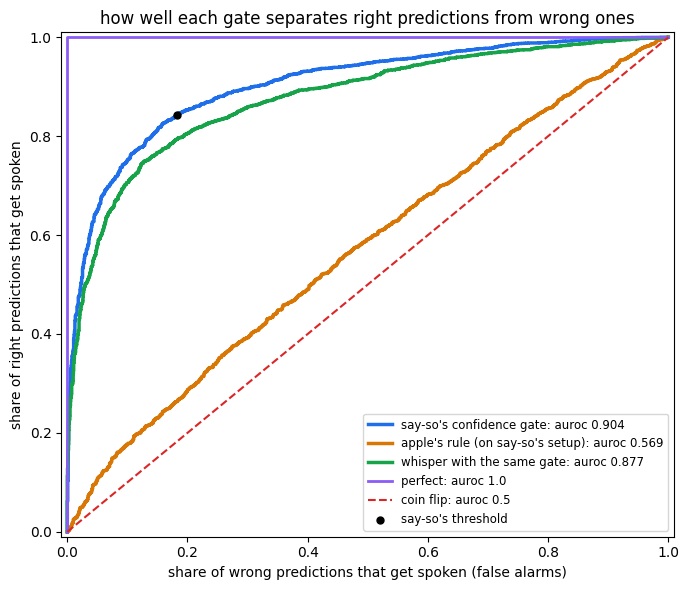

at say-so's threshold: 84.3 % of right predictions are spoken and 18.2 % of wrong ones


In [3]:
!wget -q -O dist.pkl https://raw.githubusercontent.com/mofe-stack/say-so/main/data/dist.pkl
!wget -q -O whisper_test.csv https://raw.githubusercontent.com/mofe-stack/say-so/main/data/whisper_test.csv

import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold

dist = pickle.load(open("dist.pkl", "rb"))
sig = pd.DataFrame({"dur": np.concatenate([d["test_dur"] for d in dist.values()]),
                    "loud": np.concatenate([d["test_loud"] for d in dist.values()])},
                   index=np.concatenate([d["test_clip"] for d in dist.values()]))

TARGET = 0.05
def find_cutoff(score, right):
    order = np.argsort(-score)
    wrong_spoken = np.cumsum(~right[order]) / len(right)
    allowed = np.where(wrong_spoken <= TARGET)[0]
    return score[order][allowed[-1]] if len(allowed) else np.inf

rows = []
for spk, d in dist.items():
    D, sw = d["D_test"], d["saved_word"]
    phrases = np.unique(sw)
    per_phrase = np.stack([D[:, sw == p].min(1) for p in phrases], 1)
    order = per_phrase.argsort(1)
    spread = {p: d["D_saved"][np.ix_(sw == p, sw == p)][~np.eye((sw == p).sum(), dtype=bool)].max() for p in phrases}
    for k in range(len(D)):
        d1, d2 = per_phrase[k, order[k, 0]], per_phrase[k, order[k, 1]]
        picked = phrases[order[k, 0]]
        rows.append({"speaker": spk, "sev": d["sev"], "clip": d["test_clip"][k], "word": d["test_word"][k],
                     "picked": picked, "was_saved": d["test_word"][k] in phrases,
                     "in_top3": d["test_word"][k] in phrases[order[k, :3]],
                     "best": d1, "gap": d2 - d1, "agree": D[k, sw == picked].mean() - d1,
                     "apple": d1 / spread[picked]})

g2 = pd.DataFrame(rows).merge(sig, left_on="clip", right_index=True).reset_index(drop=True)
g2 = g2[g2["was_saved"]].reset_index(drop=True)
clues = ["best", "gap", "agree", "dur", "loud"]
X, right, in3 = g2[clues].values, (g2["word"] == g2["picked"]).values, g2["in_top3"].values
make = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(X, g2["sev"], groups=g2["speaker"]))

sure, spoke = np.zeros(len(X)), np.zeros(len(X), bool)
for tr, te in folds:
    m = make().fit(X[tr], right[tr])
    sure[te] = m.predict_proba(X[te])[:, 1]
    spoke[te] = sure[te] >= find_cutoff(m.predict_proba(X[tr])[:, 1], right[tr])

w = g2.merge(pd.read_csv("whisper_test.csv"), on="clip")
w_clues = ["w_score", "w_gap", "dur", "loud"]
w_right, w_sure = (w["w_pick"] == w["word"]).values, np.zeros(len(w))
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(w, w["sev"], groups=w["speaker"]):
    wm = make().fit(w.loc[tr, w_clues].values, w_right[tr])
    w_sure[te] = wm.predict_proba(w.loc[te, w_clues].values)[:, 1]
print("whisper test recordings:", len(w), "| whisper right:", round(w_right.mean() * 100, 1), "%")

curves = [("say-so's confidence gate", right, sure, (0.122, 0.435, 0.922)),
          ("apple's rule (on say-so's setup)", right, -g2["apple"].values, (0.851, 0.467, 0.024)),
          ("whisper with the same gate", w_right, w_sure, (0.086, 0.639, 0.290))]
fig, ax = plt.subplots(figsize=(7, 6))
for name, y, score, color in curves:
    fpr, tpr, _ = roc_curve(y, score)
    ax.plot(fpr, tpr, color=color, lw=2.5, label=f"{name}: auroc {roc_auc_score(y, score):.3f}")
ax.plot([0, 0, 1], [0, 1, 1], color=(0.545, 0.361, 0.965), lw=2, label="perfect: auroc 1.0")
ax.plot([0, 1], [0, 1], "--", color=(0.863, 0.149, 0.149), lw=1.5, label="coin flip: auroc 0.5")

x_dot, y_dot = (spoke & ~right).sum() / (~right).sum(), (spoke & right).sum() / right.sum()
ax.scatter([x_dot], [y_dot], s=25, color="black", zorder=5, label="say-so's threshold")
ax.set_xlabel("share of wrong predictions that get spoken (false alarms)")
ax.set_ylabel("share of right predictions that get spoken")
ax.set_title("how well each gate separates right predictions from wrong ones")
ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.savefig("roc.png", dpi=200); plt.show()
print("at say-so's threshold:", round(y_dot * 100, 1), "% of right predictions are spoken and", round(x_dot * 100, 1), "% of wrong ones")

In [ ]:
who_said = meta.loc[both["clip"], "speaker"].values
sex2 = pd.Series(who_said).str[0].map({"f": "women", "m": "men"}).values
print((both.groupby(sex2)[["whisper", "tool"]].mean() * 100).round(1).to_string())
print()
print((both.groupby([sex2, both["sev"].values])[["whisper", "tool"]].mean() * 100).round(1).to_string())

       whisper  tool
men       55.1  69.9
women     46.7  77.5

         whisper  tool
men   1     71.7  87.9
      2     52.8  58.0
      3     20.5  41.4
women 1     46.2  76.6
      2     49.1  81.0


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

if "pairs1" not in globals() or len(pairs1) < len(dist):
    pairs1 = pickle.load(open("pairs1.pkl", "rb")) if os.path.exists("pairs1.pkl") else {}
    for spk in tqdm([s for s in dist if s not in pairs1]):
        seq, dur, loud = {}, {}, {}
        ids = meta.index[meta["speaker"] == spk].values
        for start in range(0, len(ids), 32):
            batch, clips, spans = [], [], []
            for i in ids[start:start + 32]:
                x = np.asarray(full[int(i)]["audio"]["array"], dtype=np.float32)
                if not 0.2 <= len(x) / 16000 <= 30:
                    continue
                dur[i], loud[i] = len(x) / 16000, float(np.sqrt((x ** 2).mean()))
                spans.append(tuple(librosa.effects.trim(x, top_db=30)[1])); clips.append(x); batch.append(i)
            if not clips:
                continue
            feats = fe(clips, sampling_rate=16000, return_tensors="pt").input_features.to(DEVICE, DTYPE)
            with torch.no_grad():
                heard = listener(feats).last_hidden_state.float()
            for row, i in enumerate(batch):
                first = min(spans[row][0] // 320, 1498)
                last = max(first + 2, min(1500, -(-spans[row][1] // 320)))
                steps = int(min(200, max(1, (last - first) // 2)))
                seq[i] = F.adaptive_avg_pool1d(heard[row, first:last].T[None], steps)[0].T.cpu().numpy()

        g = meta.loc[sorted(seq)]
        day_number = {s: k + 1 for k, s in enumerate(sorted(g["session"].unique()))}
        g = g.assign(day=g["session"].map(day_number)).sort_values("day", kind="stable")

        frames = np.concatenate([seq[i] for i in g.index[g["day"] == 1]])
        mid, spread = frames.mean(0), frames.std(0) + 1e-6
        S = []
        for i in g.index:
            z = (seq[i] - mid) / spread
            S.append(np.ascontiguousarray(z / np.linalg.norm(z, axis=1, keepdims=True), dtype=np.float32))
        lens = np.array([len(z) for z in S])
        T = np.zeros((len(S), lens.max(), 768), dtype=np.float32)
        for k, z in enumerate(S):
            T[k, :len(z)] = z

        pairs1[spk] = {"sev": level[g.index[0]], "word": g["word"].values, "day": g["day"].values,
                       "dur": np.array([dur[i] for i in g.index]), "loud": np.array([loud[i] for i in g.index]),
                       "D": np.stack([dtw_many(z, T, lens) for z in S])}
        pickle.dump(pairs1, open("pairs1.pkl", "wb"))
    files.download("pairs1.pkl")

def look(p, i, saved):
    phrases, which = np.unique(p["word"][saved], return_inverse=True)
    closest = np.full(len(phrases), np.inf)
    np.minimum.at(closest, which, p["D"][i, saved])
    order = np.argsort(closest)
    best = closest[order[0]]
    clues = [best, closest[order[1]] - best, p["D"][i, saved][which == order[0]].mean() - best, p["dur"][i], p["loud"][i]]
    return phrases[order[:3]], clues

def examples(spk):
    p, rows = pairs1[spk], []
    for start_days in [1, 3]:
        saved = list(np.where(p["day"] <= start_days)[0])
        for i in np.where(p["day"] > start_days)[0]:
            top, clues = look(p, i, saved)
            rows.append(clues + [top[0] == p["word"][i], p["word"][i] in top])
    return np.array(rows, dtype=float)

from sklearn.model_selection import StratifiedKFold
speakers = np.array(list(pairs1))
sevs = np.array([pairs1[s]["sev"] for s in speakers])
made = {s: examples(s) for s in speakers}
gates = {}
for a, b in StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(speakers, sevs):
    E = np.concatenate([made[s] for s in speakers[a]])
    X, right, in3_label = E[:, :5], E[:, 5].astype(bool), E[:, 6].astype(bool)
    speak = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, right)
    in3 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, in3_label)
    for s in speakers[b]:
        gates[s] = (speak, find_cutoff(speak.predict_proba(X)[:, 1], right), in3)

def use_tool(spk, start_days, keep_learning):
    p = pairs1[spk]
    speak, bar, in3 = gates[spk]
    saved = list(np.where(p["day"] <= start_days)[0])
    out = []
    for i in np.where(p["day"] > start_days)[0]:
        top, clues = look(p, i, saved)
        truth = p["word"][i]
        top_right, in_top3 = top[0] == truth, truth in top
        if speak.predict_proba([clues])[0, 1] >= bar:
            did = "spoke right" if top_right else "spoke wrong"
        elif in3.predict_proba([clues])[0, 1] >= 0.5:
            did = "showed 3, right one there" if in_top3 else "showed 3, right one missing"
        else:
            did = "stayed silent"
        have = int((p["word"][saved] == truth).sum())
        out.append((p["sev"], min(int(p["day"][i]), 6), top_right, in_top3, did, min(have, 5)))
        if keep_learning and in_top3 and did != "stayed silent":
            saved.append(i)
    return out, len(saved) / len(np.unique(p["word"][saved]))

versions = [("save 1 day, never add", 1, False), ("save 1 day, keep learning", 1, True),
            ("save 3 days, never add", 3, False), ("save 3 days, keep learning", 3, True)]
names = [v[0] for v in versions]
rows, per_phrase = [], {}
for name, start_days, keep_learning in versions:
    sizes = []
    for spk in speakers:
        out, size = use_tool(spk, start_days, keep_learning)
        rows += [(name,) + o for o in out]
        sizes.append(size)
    per_phrase[name] = np.mean(sizes)

every_day = pd.DataFrame(rows, columns=["version", "sev", "day", "top guess right", "in top 3", "did", "saved of that phrase"])
learn = every_day[every_day["day"] >= 4]

t = (pd.crosstab(learn["version"], learn["did"], normalize="index") * 100).reindex(names)
t.insert(0, "in top 3", learn.groupby("version")["in top 3"].mean() * 100)
t.insert(0, "top guess right", learn.groupby("version")["top guess right"].mean() * 100)
t["recordings per phrase at the end"] = pd.Series(per_phrase)
print("all speakers, day 4 onward")
print(t.round(1).T.to_string())

for col in ["top guess right", "in top 3"]:
    print("\n" + col + ", by severity")
    print((learn.pivot_table(index="version", columns="sev", values=col).reindex(names) * 100).round(1).to_string())

by_day = every_day.pivot_table(index="version", columns="day", values="top guess right").reindex(names) * 100
by_day.columns = ["day 2", "day 3", "day 4", "day 5", "day 6 and later"]
print("\ntop guess right, day by day")
print(by_day.round(1).to_string())

grew = every_day[every_day["version"] == names[1]].groupby("saved of that phrase")["top guess right"].agg(["mean", "count"])
grew["mean"] *= 100
grew.index = [f"{n} saved" if n < 5 else "5 or more saved" for n in grew.index]
grew.columns = ["top guess right", "recordings"]
print("\nkeep learning: top guess right, by how many recordings of that phrase were saved at the time")
print(grew.round(1).to_string())

  0%|          | 0/27 [00:00<?, ?it/s]

all speakers, day 4 onward
version                           save 1 day, never add  save 1 day, keep learning  save 3 days, never add  save 3 days, keep learning
did                                                                                                                                   
top guess right                                    54.3                       58.7                    72.8                        72.2
in top 3                                           64.0                       66.2                    83.1                        82.9
showed 3, right one missing                         9.5                       12.6                     7.0                         7.4
showed 3, right one there                          13.4                       10.7                    16.7                        15.0
spoke right                                        38.5                       49.0                    57.4                        59.9
spoke wrong                 

In [ ]:
def use_tool_corrected(spk, start_days):
    p = pairs1[spk]
    speak, bar, in3 = gates[spk]
    saved = list(np.where(p["day"] <= start_days)[0])
    out = []
    for i in np.where(p["day"] > start_days)[0]:
        top, clues = look(p, i, saved)
        truth = p["word"][i]
        top_right, in_top3 = top[0] == truth, truth in top
        if speak.predict_proba([clues])[0, 1] >= bar:
            did = "spoke right" if top_right else "spoke wrong"
        elif in3.predict_proba([clues])[0, 1] >= 0.5:
            did = "showed 3, right one there" if in_top3 else "showed 3, right one missing"
        else:
            did = "stayed silent"
        out.append((p["sev"], min(int(p["day"][i]), 6), top_right, in_top3, did))
        saved.append(i)
    return out

for start_days in [1, 3]:
    rows = [r for spk in speakers for r in use_tool_corrected(spk, start_days)]
    c = pd.DataFrame(rows, columns=["sev", "day", "top guess right", "in top 3", "did"])
    late = c[c["day"] >= 4]
    print(f"\nsave {start_days} day(s), keep learning, person corrects every miss (day 4 onward)")
    print("top guess right:", round(late["top guess right"].mean() * 100, 1), "| in top 3:", round(late["in top 3"].mean() * 100, 1))
    print((late["did"].value_counts(normalize=True) * 100).round(1).to_string())
    print("by severity:", (late.groupby("sev")["top guess right"].mean() * 100).round(1).to_dict())
    print("by day:", (c.groupby("day")["top guess right"].mean() * 100).round(1).to_dict())


save 1 day(s), keep learning, person corrects every miss (day 4 onward)
top guess right: 73.5 | in top 3: 84.2
did
spoke right                    60.7
showed 3, right one there      16.0
stayed silent                  10.6
showed 3, right one missing     7.7
spoke wrong                     5.0
by severity: {'1': 84.2, '2': 67.5, '3': 40.4}
by day: {2: 50.3, 3: 63.6, 4: 68.2, 5: 74.4, 6: 78.4}

save 3 day(s), keep learning, person corrects every miss (day 4 onward)
top guess right: 73.5 | in top 3: 84.2
did
spoke right                    60.7
showed 3, right one there      16.0
stayed silent                  10.6
showed 3, right one missing     7.7
spoke wrong                     5.0
by severity: {'1': 84.2, '2': 67.5, '3': 40.4}
by day: {4: 68.2, 5: 74.4, 6: 78.4}


In [ ]:
if "pairs_clear" not in globals() or len(pairs_clear) < len(dist_clear):
    pairs_clear = pickle.load(open("pairs_clear.pkl", "rb")) if os.path.exists("pairs_clear.pkl") else {}
    for spk in tqdm([s for s in dist_clear if s not in pairs_clear]):
        seq, dur, loud = {}, {}, {}
        ids = meta.index[meta["speaker"] == spk].values
        for start in range(0, len(ids), 32):
            batch, clips, spans = [], [], []
            for i in ids[start:start + 32]:
                x = np.asarray(full[int(i)]["audio"]["array"], dtype=np.float32)
                if not 0.2 <= len(x) / 16000 <= 30:
                    continue
                dur[i], loud[i] = len(x) / 16000, float(np.sqrt((x ** 2).mean()))
                spans.append(tuple(librosa.effects.trim(x, top_db=30)[1])); clips.append(x); batch.append(i)
            if not clips:
                continue
            feats = fe(clips, sampling_rate=16000, return_tensors="pt").input_features.to(DEVICE, DTYPE)
            with torch.no_grad():
                heard = listener(feats).last_hidden_state.float()
            for row, i in enumerate(batch):
                first = min(spans[row][0] // 320, 1498)
                last = max(first + 2, min(1500, -(-spans[row][1] // 320)))
                steps = int(min(200, max(1, (last - first) // 2)))
                seq[i] = F.adaptive_avg_pool1d(heard[row, first:last].T[None], steps)[0].T.cpu().numpy()

        g = meta.loc[sorted(seq)]
        day_number = {s: k + 1 for k, s in enumerate(sorted(g["session"].unique()))}
        g = g.assign(day=g["session"].map(day_number)).sort_values("day", kind="stable")
        frames = np.concatenate([seq[i] for i in g.index[g["day"] == 1]])
        mid, spread = frames.mean(0), frames.std(0) + 1e-6
        S = []
        for i in g.index:
            z = (seq[i] - mid) / spread
            S.append(np.ascontiguousarray(z / np.linalg.norm(z, axis=1, keepdims=True), dtype=np.float32))
        lens = np.array([len(z) for z in S])
        T = np.zeros((len(S), lens.max(), 768), dtype=np.float32)
        for k, z in enumerate(S):
            T[k, :len(z)] = z

        pairs_clear[spk] = {"sev": "0", "word": g["word"].values, "day": g["day"].values,
                            "dur": np.array([dur[i] for i in g.index]), "loud": np.array([loud[i] for i in g.index]),
                            "D": np.stack([dtw_many(z, T, lens) for z in S])}
        pickle.dump(pairs_clear, open("pairs_clear.pkl", "wb"))
    files.download("pairs_clear.pkl")

E = np.concatenate([made[s] for s in speakers])
X, right_all = E[:, :5], E[:, 5].astype(bool)
speak_all = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, right_all)
in3_all = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, E[:, 6].astype(bool))
bar_all = find_cutoff(speak_all.predict_proba(X)[:, 1], right_all)

def use_tool_clear(p, start_days, rule):
    saved = list(np.where(p["day"] <= start_days)[0])
    out = []
    for i in np.where(p["day"] > start_days)[0]:
        top, clues = look(p, i, saved)
        truth = p["word"][i]
        top_right, in_top3 = top[0] == truth, truth in top
        if speak_all.predict_proba([clues])[0, 1] >= bar_all:
            did = "spoke right" if top_right else "spoke wrong"
        elif in3_all.predict_proba([clues])[0, 1] >= 0.5:
            did = "showed 3, right one there" if in_top3 else "showed 3, right one missing"
        else:
            did = "stayed silent"
        have = int((p["word"][saved] == truth).sum())
        out.append((min(int(p["day"][i]), 6), top_right, in_top3, did, min(have, 5)))
        if rule == "always" or (rule == "confirm" and in_top3 and did != "stayed silent"):
            saved.append(i)
    return out, len(saved) / len(np.unique(p["word"][saved]))

clear_versions = [("save 1, never add", 1, "never"), ("save 1, add confirmed", 1, "confirm"),
                  ("save 1, correct every miss", 1, "always"),
                  ("save 3, never add", 3, "never"), ("save 3, add confirmed", 3, "confirm")]
names = [v[0] for v in clear_versions]
rows, per_phrase = [], {}
for name, start_days, rule in clear_versions:
    sizes = []
    for p in pairs_clear.values():
        out, size = use_tool_clear(p, start_days, rule)
        rows += [(name,) + o for o in out]
        sizes.append(size)
    per_phrase[name] = np.mean(sizes)

clear_days = pd.DataFrame(rows, columns=["version", "day", "top guess right", "in top 3", "did", "saved of that phrase"])
clear_late = clear_days[clear_days["day"] >= 4]

t = (pd.crosstab(clear_late["version"], clear_late["did"], normalize="index") * 100).reindex(names)
t.insert(0, "in top 3", clear_late.groupby("version")["in top 3"].mean() * 100)
t.insert(0, "top guess right", clear_late.groupby("version")["top guess right"].mean() * 100)
t["recordings per phrase at the end"] = pd.Series(per_phrase)
print("speakers without dysarthria, day 4 onward")
print(t.round(1).T.to_string())

by_day = clear_days.pivot_table(index="version", columns="day", values="top guess right").reindex(names) * 100
by_day.columns = ["day 2", "day 3", "day 4", "day 5", "day 6 and later"]
print("\ntop guess right, day by day")
print(by_day.round(1).to_string())

print("\nstayed silent, day by day")
quiet = clear_days.assign(silent=clear_days["did"] == "stayed silent").pivot_table(index="version", columns="day", values="silent").reindex(names) * 100
quiet.columns = ["day 2", "day 3", "day 4", "day 5", "day 6 and later"]
print(quiet.round(1).to_string())

  0%|          | 0/24 [00:00<?, ?it/s]

speakers without dysarthria, day 4 onward
version                           save 1, never add  save 1, add confirmed  save 1, correct every miss  save 3, never add  save 3, add confirmed
did                                                                                                                                             
top guess right                                82.4                   87.2                        90.8               90.4                   90.4
in top 3                                       89.6                   91.8                        95.8               94.9                   95.3
showed 3, right one missing                     2.8                    3.3                         1.9                1.5                    2.1
showed 3, right one there                       6.8                    3.4                         3.8                4.3                    3.7
spoke right                                    76.6                   84.9              

In [ ]:
def by_day(df, what):
    t = df.assign(hit=df["did"] == what).pivot_table(index="version", columns="day", values="hit", sort=False) * 100
    t.columns = [f"day {d}" for d in t.columns]
    return t.round(1)

fixed = []
for start_days in [1, 3]:
    for spk in speakers:
        fixed += [(f"save {start_days}, correct every miss",) + r for r in use_tool_corrected(spk, start_days)]
fixed = pd.DataFrame(fixed, columns=["version", "sev", "day", "top guess right", "in top 3", "did"])
dys_days = pd.concat([every_day[["version", "day", "did"]], fixed[["version", "day", "did"]]])

for what in ["spoke right", "spoke wrong", "stayed silent"]:
    print("\npeople with dysarthria:", what, "day by day")
    print(by_day(dys_days, what).to_string())
    print("\npeople without dysarthria:", what, "day by day")
    print(by_day(clear_days, what).to_string())


people with dysarthria: spoke right day by day
                            day 2  day 3  day 4  day 5  day 6
version                                                      
save 1 day, never add        41.1   37.2   39.1   36.2   40.4
save 1 day, keep learning    39.4   41.7   46.0   48.1   53.1
save 3 days, never add        NaN    NaN   56.7   55.9   59.7
save 3 days, keep learning    NaN    NaN   55.6   58.9   65.5
save 1, correct every miss   38.1   50.8   55.0   60.6   67.0
save 3, correct every miss    NaN    NaN   55.0   60.6   67.0

people without dysarthria: spoke right day by day
                            day 2  day 3  day 4  day 5  day 6
version                                                      
save 1, never add            80.8   80.3   76.5   75.1   78.0
save 1, add confirmed        79.1   84.2   82.5   84.1   87.6
save 1, correct every miss   78.9   87.5   86.4   88.1   90.9
save 3, never add             NaN    NaN   87.7   86.7   87.7
save 3, add confirmed         NaN

In [ ]:
def split_silent(df):
    d = df[["version", "day", "top guess right", "did"]].copy()
    silent, right = d["did"] == "stayed silent", d["top guess right"].astype(bool)
    d.loc[silent & right, "did"] = "silent but right"
    d.loc[silent & ~right, "did"] = "silent and wrong"
    return d

for group, d in [("people with dysarthria", split_silent(pd.concat([every_day, fixed]))),
                 ("people without dysarthria", split_silent(clear_days))]:
    order = list(d["version"].unique())
    late = d[d["day"] >= 4]
    print("\n" + group + ", day 4 onward")
    print((pd.crosstab(late["version"], late["did"], normalize="index") * 100).reindex(order).round(1).to_string())
    for what in ["silent but right", "silent and wrong"]:
        print("\n" + group + ": " + what + ", day by day")
        print(by_day(d, what).to_string())


people with dysarthria, day 4 onward
did                         showed 3, right one missing  showed 3, right one there  silent and wrong  silent but right  spoke right  spoke wrong
version                                                                                                                                         
save 1 day, never add                               9.5                       13.4              27.1               5.9         38.5          5.6
save 1 day, keep learning                          12.6                       10.7              17.8               2.8         49.0          7.2
save 3 days, never add                              7.0                       16.7              10.9               3.8         57.4          4.4
save 3 days, keep learning                          7.4                       15.0              10.1               2.7         59.9          5.0
save 1, correct every miss                          7.7                       16.0          

In [ ]:
!wget -q -O pairs1.pkl https://raw.githubusercontent.com/mofe-stack/say-so/main/data/pairs1.pkl

import pickle
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

pairs1 = pickle.load(open("pairs1.pkl", "rb"))
TARGET = 0.05

def find_cutoff(score, right):
    order = np.argsort(-score)
    wrong_spoken = np.cumsum(~right[order]) / len(right)
    allowed = np.where(wrong_spoken <= TARGET)[0]
    return score[order][allowed[-1]] if len(allowed) else np.inf

def look(p, i, saved):
    phrases, which = np.unique(p["word"][saved], return_inverse=True)
    closest = np.full(len(phrases), np.inf)
    np.minimum.at(closest, which, p["D"][i, saved])
    order = np.argsort(closest)
    best = closest[order[0]]
    clues = [best, closest[order[1]] - best, p["D"][i, saved][which == order[0]].mean() - best, p["dur"][i], p["loud"][i]]
    return phrases[order[:3]], clues

def examples(spk):
    p, rows = pairs1[spk], []
    for start in [1, 3]:
        saved = list(np.where(p["day"] <= start)[0])
        for i in np.where(p["day"] > start)[0]:
            top, clues = look(p, i, saved)
            rows.append(clues + [top[0] == p["word"][i]])
    return np.array(rows, dtype=float)

speakers = np.array(list(pairs1))
sevs = np.array([pairs1[s]["sev"] for s in speakers])
made = {s: examples(s) for s in speakers}
gates = {}
for a, b in StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(speakers, sevs):
    E = np.concatenate([made[s] for s in speakers[a]])
    X, right = E[:, :5], E[:, 5].astype(bool)
    speak = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, right)
    for s in speakers[b]:
        gates[s] = (speak, find_cutoff(speak.predict_proba(X)[:, 1], right))

def use_say_so(spk, learning):
    p = pairs1[spk]
    speak, threshold = gates[spk]
    saved = list(np.where(p["day"] <= 1)[0])
    out = []
    for i in np.where(p["day"] > 1)[0]:
        top, clues = look(p, i, saved)
        truth = p["word"][i]
        top_right, in_top3 = top[0] == truth, truth in top
        spoke = speak.predict_proba([clues])[0, 1] >= threshold
        out.append((min(int(p["day"][i]), 6), top_right, in_top3, spoke))
        if learning == "every recording" or (learning == "only when the right word is in the top three" and in_top3):
            saved.append(i)
    return out

versions = ["no learning", "only when the right word is in the top three", "every recording"]
rows = []
for v in versions:
    for spk in speakers:
        rows += [(v,) + o for o in use_say_so(spk, v)]
df = pd.DataFrame(rows, columns=["learning", "session", "prediction right", "in top three", "spoke"])

by_session = df.pivot_table(index="learning", columns="session", values="prediction right").reindex(versions) * 100
by_session.columns = ["session 2", "session 3", "session 4", "session 5", "session 6"]
print("say-so starts with one saved recording of each phrase. prediction right, by session")
print(by_session.round(1).to_string())

later = df[df["session"] >= 4]
summary = pd.DataFrame({
    "spoke and right": later.groupby("learning").apply(lambda d: (d["spoke"] & d["prediction right"]).mean() * 100),
    "false alarms": later.groupby("learning").apply(lambda d: (d["spoke"] & ~d["prediction right"]).mean() * 100),
    "showed three": later.groupby("learning").apply(lambda d: (~d["spoke"]).mean() * 100),
}).reindex(versions)
print("\nsessions 4 to 6")
print(summary.round(1).to_string())

say-so starts with one saved recording of each phrase. prediction right, by session
                                              session 2  session 3  session 4  session 5  session 6
learning                                                                                           
no learning                                        54.4       50.6       55.6       52.5       54.8
only when the right word is in the top three       52.1       52.7       58.4       59.9       63.7
every recording                                    50.3       63.6       68.2       74.4       78.4

sessions 4 to 6
                                              spoke and right  false alarms  showed three
learning                                                                                 
no learning                                              38.5           5.6          55.9
only when the right word is in the top three             50.8           7.4          41.9
every recording                        